# House Price Prediction Using Machine Learning

## Artificial Intelligence and Machine Learning – Continuous Evaluation 1

### Project Overview

House prices are influenced by several factors such as location, overall quality,
living area, number of rooms, age of the property, garage facilities, and other
physical characteristics.

The purpose of this project is to analyze and preprocess a housing dataset to
identify important factors influencing house prices. The dataset will be cleaned,
transformed, and prepared for future machine learning model development.

## Problem Statement

House prices vary depending on multiple property-related factors, making it
difficult to determine the appropriate price of a house manually.

This project aims to analyze housing data, identify important factors affecting
house prices, and prepare a clean and transformed dataset that can later be used
to develop a machine learning model for predicting house prices.

## Objectives

1. To understand and analyze the housing dataset and its important features.
2. To clean the dataset by handling duplicate, missing, and inconsistent data.
3. To perform Exploratory Data Analysis (EDA) and visualize important
   relationships affecting house prices.
4. To encode categorical variables and perform relevant feature engineering.
5. To prepare a cleaned and transformed dataset for future machine learning
   model development.

## Importing Required Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## Loading the Dataset

The Ames Housing dataset is used for this project. It contains various
property-related features and the target variable `SalePrice`, which represents
the final selling price of a house.

In [ ]:
df = pd.read_csv("train.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## Dataset Preview

In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Dataset Shape

This section identifies the total number of records and features available in
the dataset.

In [ ]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 1460
Number of columns: 81


## Dataset Information

This section provides information about column names, data types, and
non-null values.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## Statistical Summary of Numerical Features

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


## Important Features in the Dataset

Some important features used in this project are:

- `OverallQual`: Overall material and finish quality of the house.
- `GrLivArea`: Above-ground living area in square feet.
- `YearBuilt`: Original construction year of the house.
- `TotalBsmtSF`: Total basement area in square feet.
- `FullBath`: Number of full bathrooms.
- `GarageCars`: Size of the garage in terms of car capacity.
- `Neighborhood`: Physical location of the property.
- `SalePrice`: Final selling price of the house and the target variable.

# Data Cleaning

## Checking for Duplicate Records

In [ ]:
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [ ]:
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

No duplicate rows found.


## Checking Data Types

The dataset contains numerical and categorical features. Understanding their
data types is important before performing preprocessing.

In [ ]:
print("Data type count:\n")
print(df.dtypes.value_counts())

Data type count:

object     43
int64      35
float64     3
Name: count, dtype: int64


## Checking Unique Values in Important Categorical Columns

In [ ]:
important_categorical = [
    "Neighborhood",
    "HouseStyle",
    "KitchenQual",
    "GarageType"
]

for col in important_categorical:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts().head())


Neighborhood:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Name: count, dtype: int64

HouseStyle:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
Name: count, dtype: int64

KitchenQual:
KitchenQual
TA    735
Gd    586
Ex    100
Fa     39
Name: count, dtype: int64

GarageType:
GarageType
Attchd     870
Detchd     387
BuiltIn     88
Basment     19
CarPort      9
Name: count, dtype: int64


# Missing Values Analysis

Missing values can affect the quality of data analysis and machine learning
models. Therefore, missing values are identified and treated appropriately.

In [ ]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(f"Number of columns containing missing values: {len(missing_values)}")

missing_values.head(20)

Number of columns containing missing values: 19


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


## Handling Missing Values

Numerical columns are filled using the median value because the median is less
affected by extreme values.

Categorical columns are filled with `None`, indicating that the corresponding
feature or facility may not be available for that property.

In [ ]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in numerical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna("None")

print("Missing values have been treated.")

Missing values have been treated.


## Verifying Missing Values

In [ ]:
total_missing = df.isnull().sum().sum()

print(f"Total missing values remaining: {total_missing}")

Total missing values remaining: 0


# Exploratory Data Analysis and Visualization

EDA is performed to understand the distribution of house prices and identify
relationships between important property features and the target variable.

## Distribution of House Prices

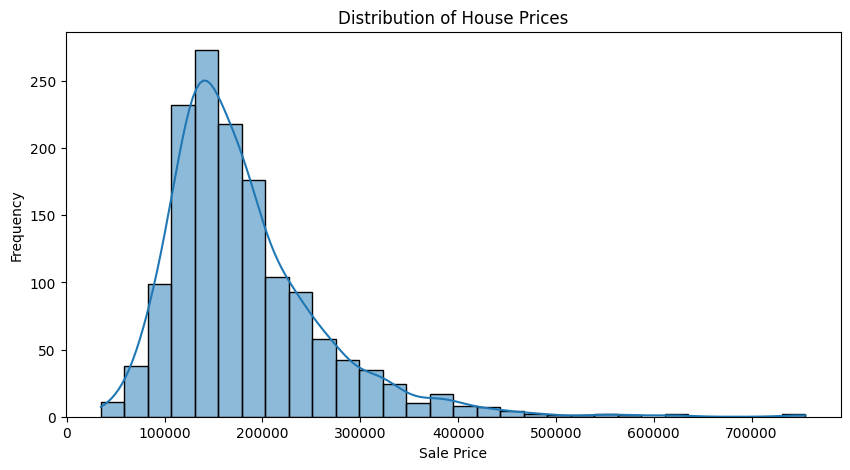

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["SalePrice"],
    kde=True,
    bins=30
)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

### Observation

The graph shows the distribution of house prices in the dataset. The shape of
the distribution helps determine whether house prices are evenly distributed or
skewed towards a particular price range.

## Overall Quality vs Sale Price

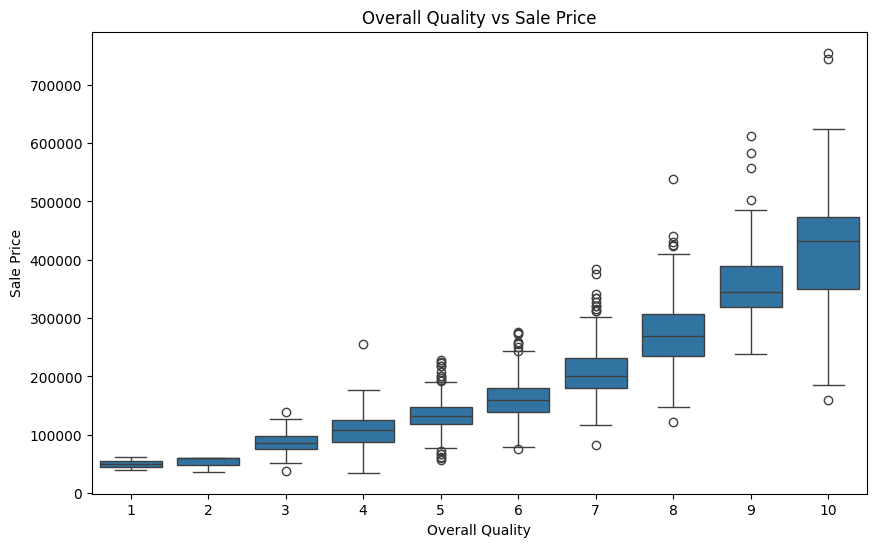

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="OverallQual",
    y="SalePrice",
    data=df
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

### Observation

The graph helps analyze the relationship between the overall quality of a house
and its selling price. Generally, houses with better overall quality are expected
to have higher sale prices.

## Living Area vs Sale Price

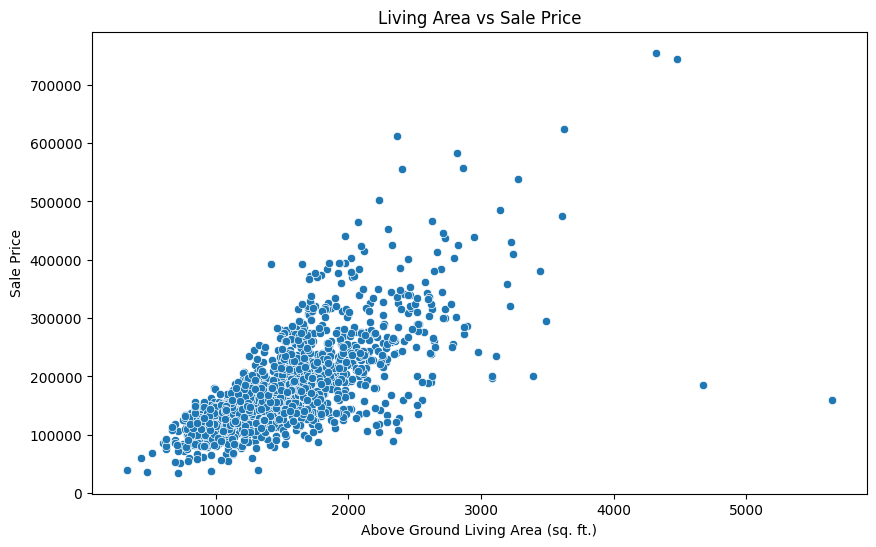

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="GrLivArea",
    y="SalePrice",
    data=df
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area (sq. ft.)")
plt.ylabel("Sale Price")
plt.show()

### Observation

This graph shows the relationship between the above-ground living area and house
price. Houses with larger living areas generally tend to have higher sale prices,
although some exceptions may exist.

## Year Built vs Sale Price

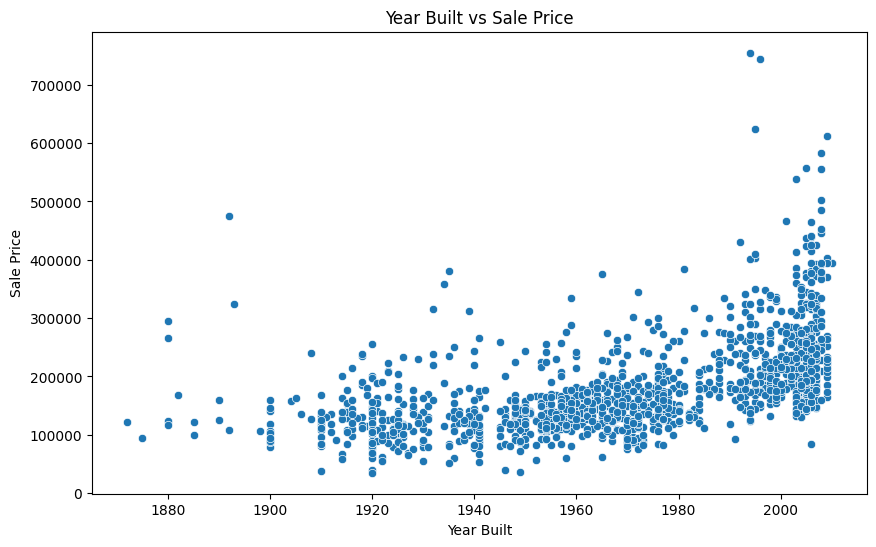

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x="YearBuilt",
    y="SalePrice",
    data=df
)

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")
plt.show()

### Observation

The graph helps determine the relationship between the construction year of a
house and its selling price. Newer houses may generally have higher prices due
to modern construction and facilities.

## Neighborhood vs Sale Price

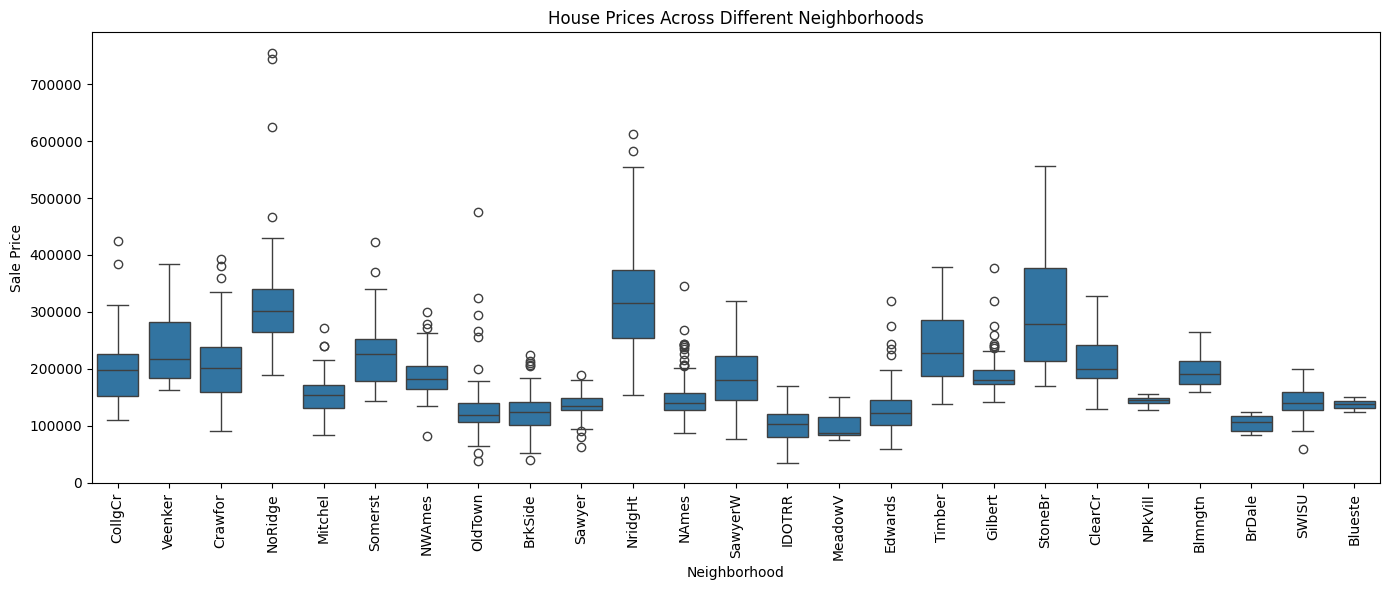

In [ ]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    x="Neighborhood",
    y="SalePrice",
    data=df
)

plt.xticks(rotation=90)
plt.title("House Prices Across Different Neighborhoods")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

### Observation

The graph compares house prices across different neighborhoods. It can be
observed that location has a significant influence on property prices.

## Garage Capacity vs Sale Price

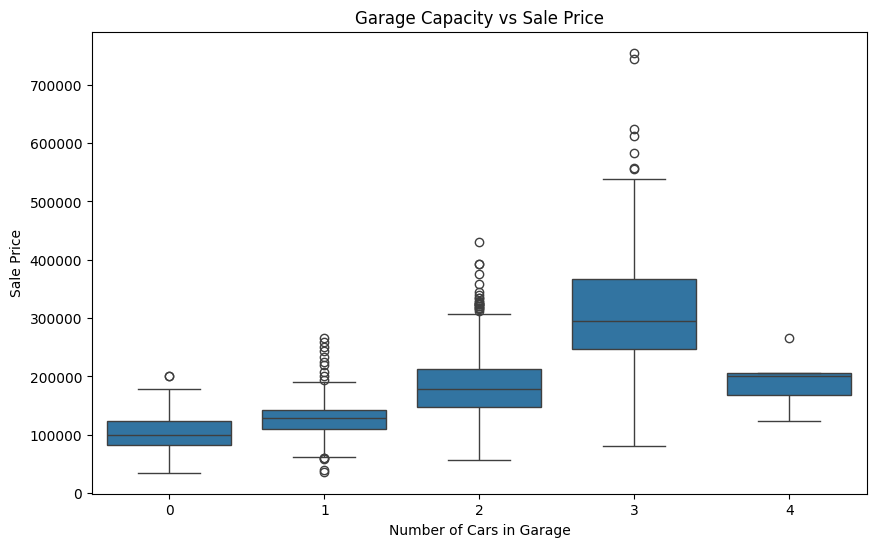

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="GarageCars",
    y="SalePrice",
    data=df
)

plt.title("Garage Capacity vs Sale Price")
plt.xlabel("Number of Cars in Garage")
plt.ylabel("Sale Price")
plt.show()

### Observation

This visualization helps analyze whether garage capacity influences house prices.
Properties with larger garage capacity may generally have higher sale prices.

# Correlation Analysis

Correlation analysis is performed to identify numerical features that have a
strong relationship with the target variable, `SalePrice`.

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

correlation_with_price = numeric_df.corr()["SalePrice"].sort_values(
    ascending=False
)

correlation_with_price.head(15)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


## Correlation Heatmap

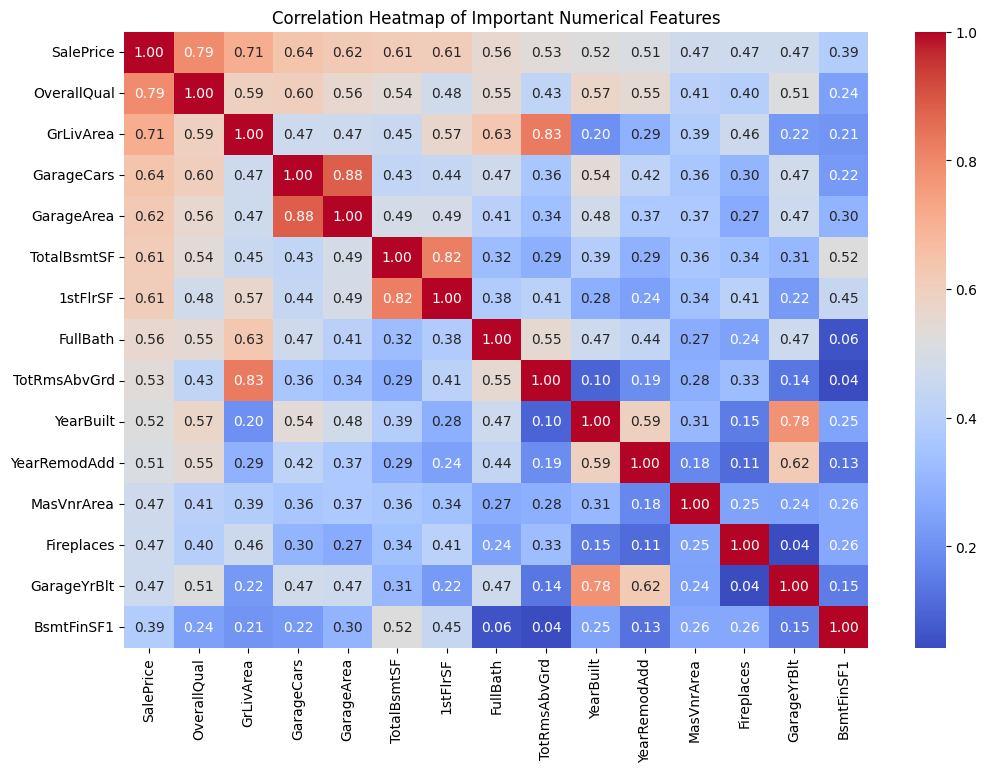

In [ ]:
top_features = correlation_with_price.abs().nlargest(15).index

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Important Numerical Features")
plt.show()

### Observation

The heatmap identifies numerical features that have strong positive or negative
relationships with `SalePrice`. Features with stronger correlations can be
considered important during feature selection.

# Feature Engineering

New meaningful features are created using existing property-related features.
Feature engineering can help represent the characteristics of a property more
effectively.

## Creating Total Area Feature

In [ ]:
df["TotalArea"] = (
    df["TotalBsmtSF"] +
    df["1stFlrSF"] +
    df["2ndFlrSF"]
)

df[["TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "TotalArea"]].head()

,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalArea
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


## Creating House Age Feature

In [ ]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

df[["YearBuilt", "YrSold", "HouseAge"]].head()

,YearBuilt,YrSold,HouseAge
0,2003,2008,5
1,1976,2007,31
2,2001,2008,7
3,1915,2006,91
4,2000,2008,8


## Creating Total Bathrooms Feature

A combined bathroom feature is created by considering full bathrooms and half
bathrooms.

In [ ]:
df["TotalBathrooms"] = (
    df["FullBath"] +
    0.5 * df["HalfBath"] +
    df["BsmtFullBath"] +
    0.5 * df["BsmtHalfBath"]
)

df[
    [
        "FullBath",
        "HalfBath",
        "BsmtFullBath",
        "BsmtHalfBath",
        "TotalBathrooms"
    ]
].head()

,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,TotalBathrooms
0,2,1,1,0,3.5
1,2,0,0,1,2.5
2,2,1,1,0,3.5
3,1,0,1,0,2.0
4,2,1,1,0,3.5


# Categorical Data Encoding

Machine learning algorithms generally require numerical input. Therefore,
categorical variables are converted into numerical form using One-Hot Encoding.

In [ ]:
categorical_cols = df.select_dtypes(include="object").columns

print(f"Number of categorical columns: {len(categorical_cols)}")

Number of categorical columns: 43


In [ ]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Categorical encoding completed.")
print(f"Dataset shape after encoding: {df_encoded.shape}")

Categorical encoding completed.
Dataset shape after encoding: (1460, 265)


# Feature Selection

The `Id` column is a unique identifier and does not provide meaningful
property-related information for predicting house prices. Therefore, it is
removed from the input features.

In [ ]:
if "Id" in df_encoded.columns:
    df_encoded = df_encoded.drop(columns="Id")

print("Irrelevant identifier column removed.")

Irrelevant identifier column removed.


## Defining Input Features (X) and Target Variable (y)

In [ ]:
X = df_encoded.drop(columns="SalePrice")
y = df_encoded["SalePrice"]

print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Shape of X: (1460, 263)
Shape of y: (1460,)


## Selecting Important Numerical Features

Correlation analysis is used to identify numerical features that have a strong
relationship with house prices.

In [ ]:
numerical_correlations = df_encoded.corr()["SalePrice"].abs().sort_values(
    ascending=False
)

print("Top features correlated with SalePrice:\n")
print(numerical_correlations.head(15))

Top features correlated with SalePrice:

SalePrice         1.000000
OverallQual       0.790982
TotalArea         0.782260
GrLivArea         0.708624
GarageCars        0.640409
TotalBathrooms    0.631731
GarageArea        0.623431
TotalBsmtSF       0.613581
1stFlrSF          0.605852
ExterQual_TA      0.589044
FullBath          0.560664
TotRmsAbvGrd      0.533723
HouseAge          0.523350
YearBuilt         0.522897
KitchenQual_TA    0.519298
Name: SalePrice, dtype: float64


# Feature Scaling

Numerical features are standardized so that their values are placed on a
comparable scale. Categorical features created through One-Hot Encoding are not
scaled.

In [ ]:
numerical_feature_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns

scaler = StandardScaler()

X_scaled = X.copy()

X_scaled[numerical_feature_cols] = scaler.fit_transform(
    X_scaled[numerical_feature_cols]
)

print("Numerical features have been standardized.")

Numerical features have been standardized.


# Final Preprocessed Dataset

The final dataset is now:

- Cleaned
- Checked for duplicate records
- Treated for missing values
- Analyzed using EDA
- Transformed using feature engineering
- Encoded for categorical variables
- Prepared with relevant input features ( Feature Selection )
- Ready for future machine learning model development

In [ ]:
final_df = X_scaled.copy()
final_df["SalePrice"] = y

print(f"Final dataset shape: {final_df.shape}")

Final dataset shape: (1460, 264)


In [ ]:
final_df.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,TotalArea,HouseAge,TotalBathrooms,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,Alley_None,Alley_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,Utilities_NoSeWa,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_PosA,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,Condition2_RRNn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,RoofMatl_CompShg,RoofMatl_Membran,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,ExterCond_Fa,ExterCond_Gd,ExterCond_Po,ExterCond_TA,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,BsmtQual_Fa,BsmtQual_Gd,BsmtQual_None,BsmtQual_TA,BsmtCond_Gd,BsmtCond_None,BsmtCond_Po,BsmtCond_TA,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,BsmtFinType1_None,BsmtFinType1_Rec,BsmtFinType1_Unf,BsmtFinType2_BLQ,BsmtFinType2_GLQ,BsmtFinType2_LwQ,BsmtFinType2_None,BsmtFinType2_Rec,BsmtFinType2_Unf,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,HeatingQC_Fa,HeatingQC_Gd,HeatingQC_Po,HeatingQC_TA,CentralAir_Y,Electrical_FuseF,Electrical_FuseP,Electrical_Mix,Electrical_None,Electrical_SBrkr,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sev,Functional_Typ,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_Po,GarageQual_TA,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_P,PavedDrive_Y,PoolQC_Fa,PoolQC_Gd,PoolQC_None,Fence_GdWo,Fence_MnPrv,Fence_MnWw,Fence_None,MiscFeature_None,MiscFeature_Othr,MiscFeature_Shed,MiscFeature_TenC,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType

## Final Dataset Verification

In [ ]:
print(f"Total missing values: {final_df.isnull().sum().sum()}")
print(f"Total duplicate rows: {final_df.duplicated().sum()}")
print(f"Final number of features: {final_df.shape[1] - 1}")

Total missing values: 0
Total duplicate rows: 0
Final number of features: 263


# Conclusion

In this project, the Ames Housing dataset was analyzed and prepared for future
machine learning model development.

The dataset was examined to understand its structure, data types, and important
features. Duplicate records and missing values were checked and treated using
appropriate methods.

Exploratory Data Analysis was performed to understand the relationship between
house prices and important features such as overall quality, living area,
construction year, neighborhood, and garage capacity.

Feature engineering was performed by creating new features such as TotalArea,
HouseAge, and TotalBathrooms. Categorical variables were transformed using
One-Hot Encoding, and the input features and target variable were clearly
defined.

The final dataset is cleaned, transformed, and ready for machine learning model
development.

# Future Scope

The next phase of the project will focus on developing machine learning models
to predict house prices.

The following steps can be performed:

1. Split the dataset into training and testing sets.
2. Train regression models such as Linear Regression.
3. Train advanced models such as Random Forest and Gradient Boosting.
4. Compare model performance using appropriate evaluation metrics.
5. Perform hyperparameter tuning to improve model performance.
6. Select the best model for predicting house prices of new properties.

# CONTINUOUS EVALUATION 2 (CE-2)
# House Price Prediction – Machine Learning Model Development

## Continuation of CE-1

In CE-1, the Ames Housing dataset was explored, cleaned, visualized and prepared. In CE-2, we will train and evaluate regression models to predict the house selling price (`SalePrice`).

### Steps in CE-2
1. Load the original dataset.
2. Create useful features.
3. Separate input features and target.
4. Split the data into training and testing sets.
5. Preprocess numerical and categorical columns.
6. Train regression models.
7. Compare models using MAE, MSE, RMSE and R².
8. Select and save the best model.
9. Visualize and interpret the predictions.

**Why reload the original dataset?** We want to split the data before learning imputation values, scaling values and category encodings. This avoids data leakage from the test set.

## 1. Importing Libraries

We use Scikit-learn for preprocessing, model training, splitting and evaluation. Matplotlib and Seaborn are used for graphs.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Loading the Dataset

Use the original Kaggle `train.csv` file. Keep it in the same folder as this notebook.

In [ ]:
df_model = pd.read_csv("/train.csv")

print("Dataset shape:", df_model.shape)
df_model.head()

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Feature Engineering

We create the same three features as in CE-1:
- `TotalArea`: total basement and above-ground floor area.
- `HouseAge`: age of the house at the time it was sold.
- `TotalBathrooms`: total full and half bathrooms, where a half bathroom is counted as 0.5.

In [ ]:
df_model = df_model.copy()

df_model["TotalArea"] = (
    df_model["TotalBsmtSF"] +
    df_model["1stFlrSF"] +
    df_model["2ndFlrSF"]
)

df_model["HouseAge"] = df_model["YrSold"] - df_model["YearBuilt"]

df_model["TotalBathrooms"] = (
    df_model["FullBath"] +
    0.5 * df_model["HalfBath"] +
    df_model["BsmtFullBath"] +
    0.5 * df_model["BsmtHalfBath"]
)

print("Feature engineering completed.")
df_model[["TotalArea", "HouseAge", "TotalBathrooms", "SalePrice"]].head()

Feature engineering completed.


,TotalArea,HouseAge,TotalBathrooms,SalePrice
0,2566,5,3.5,208500
1,2524,31,2.5,181500
2,2706,7,3.5,223500
3,2473,91,2.0,140000
4,3343,8,3.5,250000


## 4. Separating Input Features (X) and Target (y)

`X` contains the property details used for prediction. `y` contains the actual house selling price that the model learns to predict.

We remove `Id` because it is only a record identifier.

In [ ]:
X = df_model.drop(columns=["SalePrice", "Id"])
y = df_model["SalePrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 82)
y shape: (1460,)


## 5. Train-Test Split

We use 80% of the records for training and 20% for testing.

- Training data helps the model learn patterns.
- Testing data checks model performance on records it did not train on.
- `random_state=42` makes the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 1168
Testing records: 292


## 6. Identifying Numerical and Categorical Columns

Numerical columns contain numeric measurements. Categorical columns contain labels such as neighborhood, house style and garage type.

In [ ]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 39
Categorical features: 43


## 7. Preprocessing the Data

The numerical columns are filled using the median and standardized. Categorical columns are filled with `"None"` and converted into numeric columns using One-Hot Encoding.

The preprocessing is included inside each model pipeline. This means it is fitted using training data only.

In [ ]:
numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_preprocessor, numerical_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 8. Defining Regression Models

We compare four regression algorithms:

1. **Multiple Linear Regression:** predicts price using a linear combination of multiple input features. It is our simple baseline model.
2. **Decision Tree Regressor:** learns decision rules by splitting the data into smaller groups.
3. **Random Forest Regressor:** combines predictions from many decision trees.
4. **Gradient Boosting Regressor:** builds trees sequentially, where later trees try to improve earlier predictions.

All four models are suitable for a numerical target such as house price.

In [ ]:
models = {
    "Multiple Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models are ready.")

Models are ready.


## 9. Training and Evaluating the Models

Each model is trained on the training set and evaluated on the same test set.

- **MAE:** average absolute difference between actual and predicted prices.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE; it is in the same unit as house price.
- **R² Score:** indicates how much variation in house prices is explained by the model.

For MAE, MSE and RMSE, lower is better. For R², a higher value is generally better.

In [ ]:
trained_models = {}
results = []

for name, model in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    trained_models[name] = model_pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(name, "completed.")

results_df = pd.DataFrame(results).sort_values(
    by="RMSE"
).reset_index(drop=True)

results_df

Multiple Linear Regression completed.
Decision Tree completed.
Random Forest completed.
Gradient Boosting completed.


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting,17032.568259,8.177316e+08,28596.006447,0.893390
1,Random Forest,17499.883259,8.875104e+08,29791.113307,0.884293
2,Decision Tree,25250.343806,1.685361e+09,41053.144387,0.780275
3,Multiple Linear Regression,21126.270219,4.275677e+09,65388.658893,0.442569


## 10. Comparing Model Performance

This graph compares the test RMSE of the four models. A lower RMSE means lower squared prediction error on this test set.

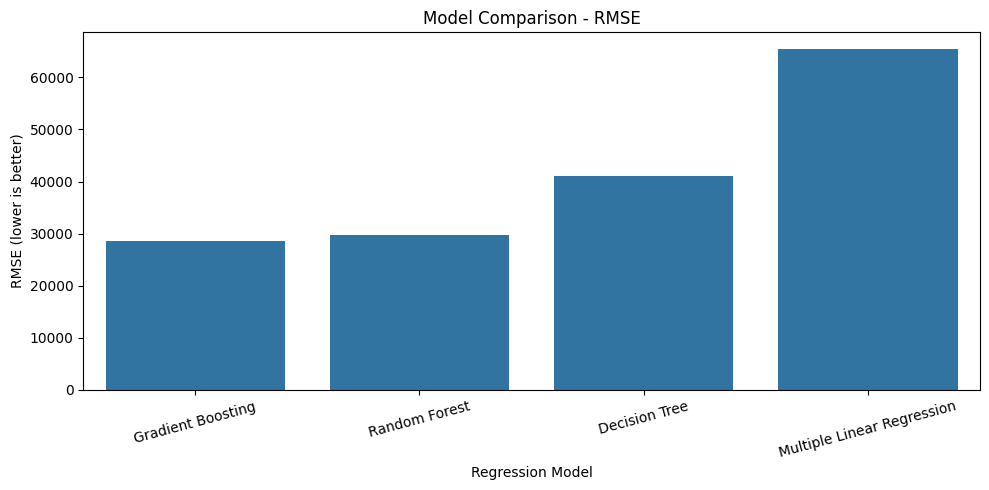

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Comparison - RMSE")
plt.xlabel("Regression Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 11. Selecting the Best Model

We select the model with the lowest RMSE on the test set. This identifies the best-performing model among the four models tested in this experiment.

In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("MAE:", round(results_df.loc[0, "MAE"], 2))
print("MSE:", round(results_df.loc[0, "MSE"], 2))
print("RMSE:", round(results_df.loc[0, "RMSE"], 2))
print("R2 Score:", round(results_df.loc[0, "R2 Score"], 4))

Selected model: Gradient Boosting
MAE: 17032.57
MSE: 817731584.71
RMSE: 28596.01
R2 Score: 0.8934


## 12. Actual Price vs Predicted Price

The diagonal line represents perfect predictions. Points closer to this line indicate predictions closer to the actual selling prices.

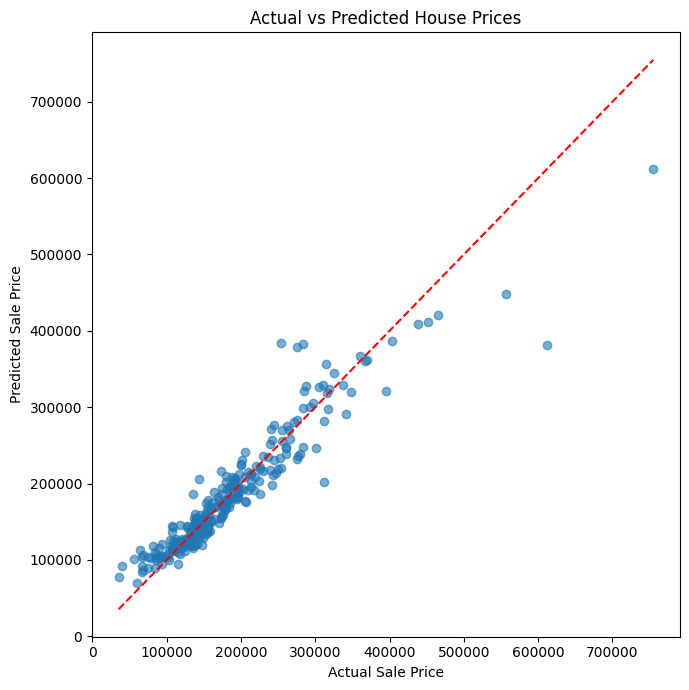

In [ ]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_predictions, alpha=0.6)

low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

## 13. Residual Analysis

A residual is the difference between actual and predicted price.

**Residual = Actual Price − Predicted Price**

A residual near zero means the prediction was close to the actual price. A visible pattern in residuals may indicate that the model is missing some relationship in the data.

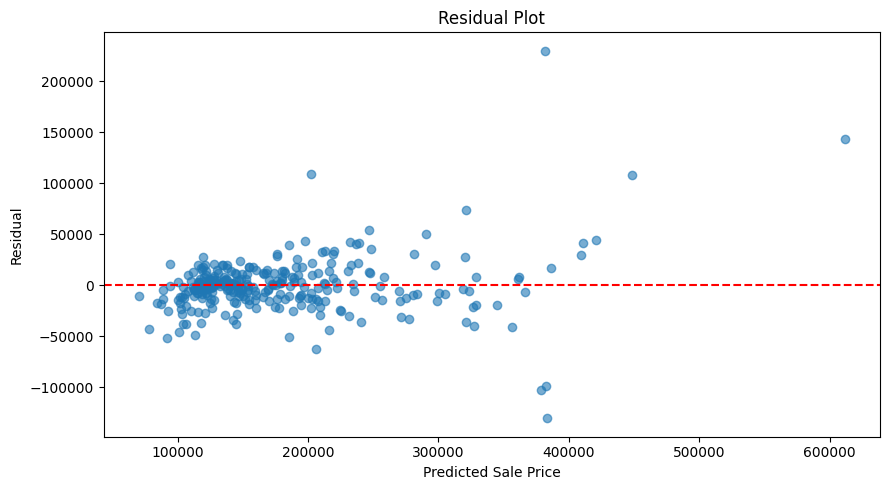

In [ ]:
residuals = y_test - best_predictions

plt.figure(figsize=(9, 5))
plt.scatter(best_predictions, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

## 14. Feature Importance using Random Forest

Random Forest provides feature-importance values that help us understand which transformed input features contributed most to its predictions.

This is an interpretation step. The final selected model is still the one chosen using the lowest test RMSE.

In [ ]:
rf_pipeline = trained_models["Random Forest"]

feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_values = rf_pipeline.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(by="Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
36,num__TotalArea,0.389111
3,num__OverallQual,0.374590
13,num__2ndFlrSF,0.025549
5,num__YearBuilt,0.012636
37,num__HouseAge,0.011950
2,num__LotArea,0.011721
25,num__GarageCars,0.010965
38,num__TotalBathrooms,0.010724
15,num__GrLivArea,0.010547
8,num__BsmtFinSF1,0.010377


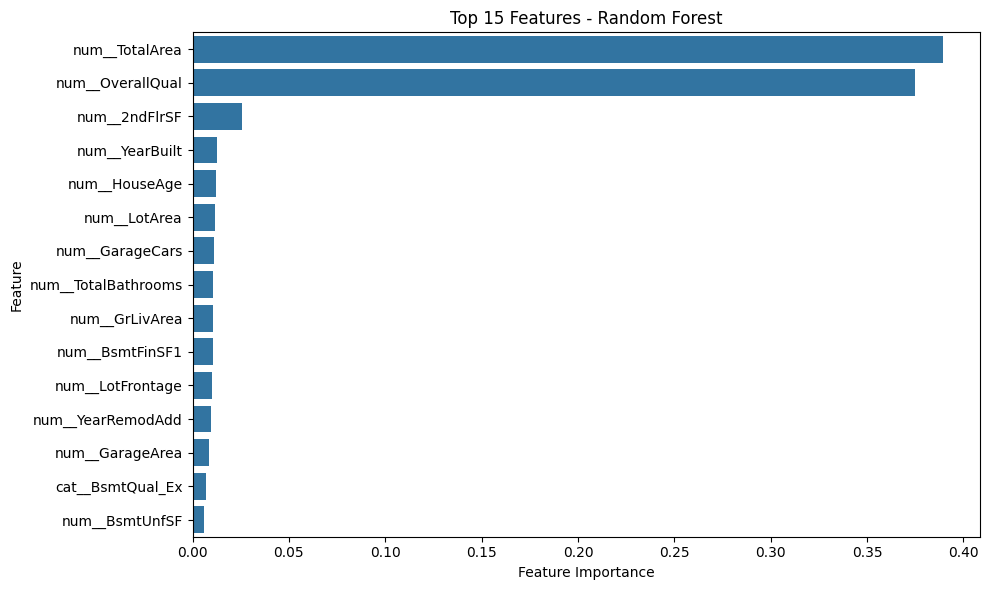

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 15. Example Prediction for One Test House

We select one record from the test set and show its actual price and predicted price. This demonstrates how the trained model predicts the price of an unseen house.

In [ ]:
sample_house = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_house)[0]

print("Actual price:", round(actual_price, 2))
print("Predicted price:", round(predicted_price, 2))
print("Difference:", round(actual_price - predicted_price, 2))

Actual price: 154500
Predicted price: 141012.3
Difference: 13487.7


## 16. Cross-Validation of the Selected Model

A single train-test split can depend on which records are selected. Cross-validation evaluates the model over multiple training/validation splits.

We use 5-fold cross-validation on the training data. Negative RMSE is returned by Scikit-learn for scoring purposes, so we multiply it by -1 to show positive RMSE values.

In [ ]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

cv_rmse_scores = -cv_scores

print("RMSE for each fold:", np.round(cv_rmse_scores, 2))
print("Average cross-validation RMSE:", round(cv_rmse_scores.mean(), 2))

RMSE for each fold: [27426.39 33243.61 33104.3  26394.51 24189.65]
Average cross-validation RMSE: 28871.69


## 17. Saving the Final Model

We save the complete pipeline, not just the algorithm. The pipeline contains preprocessing and the trained model, so new records will be processed in the same way before prediction.

In [ ]:
joblib.dump(best_model, "best_house_price_model.pkl")
print("Model saved successfully.")

Model saved successfully.


## 18. Loading and Reusing the Saved Model

We load the saved pipeline and predict the price of the same sample house again. The result should match the earlier prediction.

In [ ]:
loaded_model = joblib.load("best_house_price_model.pkl")

loaded_prediction = loaded_model.predict(sample_house)[0]

print("Prediction using saved model:", round(loaded_prediction, 2))

Prediction using saved model: 141012.3


## 19. Final Conclusion

The CE-1 House Price Prediction project has been extended to a complete regression modelling workflow. Four regression algorithms were trained and compared using MAE, MSE, RMSE and R² Score. The model with the lowest test RMSE was selected.

The actual-versus-predicted graph and residual plot were used to understand prediction performance. Random Forest feature importance was examined to interpret useful input features. The complete preprocessing and model pipeline was saved for reuse.

### Limitations
- The dataset represents houses from a specific location and time period, so results may not generalize to every housing market.
- Model performance depends on the quality and representativeness of the dataset.
- A train-test split gives one estimate of performance; cross-validation provides an additional check.

### Future Scope
- Test additional regression algorithms and tune their parameters.
- Collect more recent and geographically diverse housing data.
- Build a simple user interface where a user can enter house details and receive a predicted price.
- Periodically retrain the model when new housing data becomes available.

**Important:** Report the actual metric values generated by running this notebook. Do not write assumed or sample scores in the PPT or report.